# Batch-corrected effects and Wilcoxon tests

When a screen runs in many batches, a target's cells and the control cells are rarely spread over the
batches in the same proportions, and differences between batches then pass for effects of the
knockdown. Comparing each batch with its own controls removes them without a model of how batches
differ. This tutorial follows Liu *et al.* (2026, *bioRxiv*,
[doi:10.64898/2026.10.05.756839](https://doi.org/10.64898/2026.10.05.756839)), who processed twelve
CRISPRi screens with crispyx this way:

- **Effect:** within each batch, the difference of mean `log1p(CP10k)` between the target's cells and the
  controls; across batches, their weighted mean with weights `n_t n_c / (n_t + n_c)`. This is the
  estimate of a regression with one intercept per batch and one perturbation coefficient
  (`cx.pb.normalized_effects` with `batch_column`).
- **Standard error:** two of them. One assumes independent cells and one within-batch variance per arm;
  the robust one is taken from how the per-batch effects scatter.
- **p-values:** Wilcoxon rank-sum tests within each batch, combined over batches (van Elteren's test;
  `cx.wilcoxon_test` with `batch_column`).

> **Key results**
>
> - Comparing each of the 1,325 batches with its own controls matters: against all controls at once,
>   the Wilcoxon test calls a median of 489 hits per target, 429 of which are not hits per batch; per
>   batch it calls 75.
> - On fake targets made of non-targeting guides, the per-batch Wilcoxon test and the robust standard
>   error are close to calibrated (6.0% and 6.6% of p-values below 0.05). The model-based standard error
>   is not (14.9%, about 140 hits per fake target): it treats cells as independent.
> - The robust z-score follows the Wilcoxon z-score (median r 0.93, at about the same scale), and
>   `residual_effects` with inlet and line as covariates gives nearly the same effects (median r 0.999).

**Data.** The targeted screen of Feng *et al.* (2026, *Cell Genomics*,
[doi:10.1016/j.xgen.2025.101076](https://doi.org/10.1016/j.xgen.2025.101076)): 444 knockdowns in 1.16
million induced pluripotent stem cells from 19 lines, captured in 142 10x inlets. Each inlet pools
several lines, so a batch is an inlet and line together, 1,325 of them, as in Liu *et al.* The counts
file is the one Part 1 of [`residual_effects` in a targeted screen](residual_effects_feng_tutorial.ipynb) builds.

For effects adjusted for continuous covariates (depth, cell cycle) as well, see `residual_effects` in
that tutorial; [Covariate adjustment](../covariate_adjustment.rst) compares the approaches.

In [1]:
import os

# Progress bars off, so the saved notebook keeps only crispyx's summary lines; tqdm
# reads this when first imported, so it is set before anything imports tqdm.
os.environ.setdefault('TQDM_DISABLE', '1')

import sys
import warnings
from contextlib import contextmanager
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Paths stay relative to this notebook's directory so that the paths crispyx
# echoes in its output are the same on every machine.
ROOT = Path('../..')
sys.path.insert(0, str(ROOT / 'src'))
# A gene a group never expresses has a standard error of 0; its z-score is NaN or
# infinite and the tests below leave it out, so the division warnings are noise.
np.seterr(divide='ignore', invalid='ignore')
warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', message='Variable names are not unique')  # gene symbols repeat
import crispyx as cx

OUTPUT_DIR = Path('tutorial_outputs')
counts_path = OUTPUT_DIR / 'FengTS_counts.h5ad'

cores = len(os.sched_getaffinity(0)) if hasattr(os, 'sched_getaffinity') else os.cpu_count()
print(f'crispyx {cx.__version__}, {cores} cores')

steps = []


@contextmanager
def measured(step):
    # record a step's wall time and this process's peak memory while it runs
    with cx.Profiler(timing=True, sampling=True, memory_method='rss', sample_interval=0.5) as profiler:
        yield
    stats_ = profiler.get_stats()
    minutes = stats_['timing']['total_seconds'] / 60
    peak_gb = stats_['memory']['peak_mb'] / 1024
    steps.append({'step': step, 'wall time (min)': round(minutes, 1), 'peak RSS (GB)': round(peak_gb, 1)})
    print(f'{step}: {minutes:.1f} min, peak RSS {peak_gb:.1f} GB')


@contextmanager
def warnings_as_messages():
    # print crispyx's warnings by message only: the default banner names the source file
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        warnings.simplefilter('ignore', DeprecationWarning)
        warnings.filterwarnings('ignore', message='Variable names are not unique')
        yield
    for message in dict.fromkeys(f'{w.category.__name__}: {w.message}' for w in caught):
        print(message)

crispyx 0.2.0, 32 cores


## Part 1 — Effects and standard errors

### 1. Targets, controls and batches

Each cell's label is the target of its guide; cells with no guide or a non-targeting guide are the
controls, as in Feng *et al.* Following Liu *et al.*, a target needs at least 20 cells. Labels and batches
are passed as `pd.Series` indexed by cell, so nothing is written to the counts file. One cell without
metadata gets no label and is left out.

In [2]:
obs = cx.load_obs(counts_path)
guide = obs['Guide_Call'].astype(str)
guide_target = guide.str.split('_').str[0]
labels = (guide_target.where(~guide_target.isin(['unassigned', 'NonTarget']), 'control')
          .where(obs['Guide_Call'].notna())
          .rename('target'))
strata = (obs['inlet'].astype(str) + '|' + obs['line'].astype(str)).rename('batch')

sizes = labels[labels != 'control'].value_counts()
targets = sizes.index[sizes >= 20].tolist()
pairs = pd.crosstab(labels[labels.isin(targets)], strata[labels.isin(targets)])
print(f"{(labels == 'control').sum():,} control cells, {len(targets)} targets with at least 20 cells, "
      f"{strata.nunique():,} batches")
print(f"a target spans a median of {int(np.median((pairs > 0).sum(axis=1)))} batches, "
      f"with a median of {int(np.median(pairs.to_numpy()[pairs.to_numpy() > 0]))} cell(s) in each")

535,083 control cells, 444 targets with at least 20 cells, 1,325 batches
a target spans a median of 788 batches, with a median of 1 cell(s) in each


### 2. Effects

`cx.pb.normalized_effects` normalises each cell to `log1p` counts per 10,000 and, with `batch_column`,
compares each batch with its own controls. A batch without controls carries no contrast and is skipped.
For `method="mean_log1p"` (the default) it also writes the two standard errors:

- `standard_error`: cells independent within a batch, with one within-batch variance per arm,
  pooled over the batches that have at least two cells on that side;
- `standard_error_robust`: from the spread of the per-batch effects around their weighted mean, with no
  shared variance; it needs at least two batches.

The same call without `batch_column` gives the pooled effects, compared with all controls at once.
The per-(target, batch) sums it keeps in memory are large here, 347,000 pairs x 36,518 genes, and
`memory_limit_gb` decides whether they stay in memory or go to disk.

In [3]:
common = dict(perturbation_column=labels, control_label='control', perturbations=targets,
              gene_name_column='gene_name')
with measured('effects and standard errors, per batch'):
    stratified = cx.pb.normalized_effects(counts_path, batch_column=strata,
                                          output_path=OUTPUT_DIR / 'fengts_effects_by_batch.h5ad', **common)
with measured('effects, pooled'):
    pooled = cx.pb.normalized_effects(counts_path, output_path=OUTPUT_DIR / 'fengts_effects_pooled.h5ad',
                                      **common)
stratified

[cx] pb.normalized_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] pb.normalized_effects: chunk_size=4096 (auto)
[cx] pb.normalized_effects: estimated disk usage: 713.4 MB (441.9 GB free)
[cx] pb.normalized_effects: 444 perturbations × 36518 genes
[cx] pb.normalized_effects: Saving → tutorial_outputs/fengts_effects_by_batch.h5ad
effects and standard errors, per batch: 8.5 min, peak RSS 203.1 GB
[cx] pb.normalized_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] pb.normalized_effects: chunk_size=4096 (auto)
[cx] pb.normalized_effects: estimated disk usage: 570.7 MB (441.2 GB free)
[cx] pb.normalized_effects: 444 perturbations × 36518 genes
[cx] pb.normalized_effects: Saving → tutorial_outputs/fengts_effects_pooled.h5ad
effects, pooled: 4.1 min, peak RSS 17.1 GB


AnnData(path=tutorial_outputs/fengts_effects_by_batch.h5ad, mode='r')

The result has targets as rows and genes as columns:

| Where | What |
|---|---|
| `X` | the effect: a difference of mean `log1p(CP10k)` (natural log), **not** a log2 fold change |
| `layers` | `standard_error`, `standard_error_robust`, `perturbation_profile` and the weight-matched `control_profile_matched` |
| `uns` | `control_profile` (all controls), `batch_column`, `batch_ids` |

In [4]:
by_batch = ad.read_h5ad(stratified.path)
by_pool = ad.read_h5ad(pooled.path)
genes = pd.Index(by_batch.var_names)
effect, se, se_robust = by_batch.X, by_batch.layers['standard_error'], by_batch.layers['standard_error_robust']
ratio = np.nanmedian(se_robust / se, axis=1)
print(f'robust / model standard error, median over genes: {np.median(ratio):.2f} for the median target '
      f'(5th-95th percentile over targets {np.percentile(ratio, 5):.2f}-{np.percentile(ratio, 95):.2f})')

robust / model standard error, median over genes: 1.22 for the median target (5th-95th percentile over targets 1.19-1.24)


### 3. p-values from the stratified Wilcoxon test

A rank test needs normalised data, so the counts are normalised to `log1p(CP10k)` into a new file, and
the batches are written to its `obs`. As in Liu *et al.*, a gene is tested for a target unless its mean
`log1p(CP10k)` is below 0.08 both among the target's cells and among the controls (the fraction of
expressing cells plays no part, hence `min_pct_* = 1`). The same test against all controls at once
follows, for comparison.

A rank test reads all cells of a few genes at a time, which a matrix stored by cell (CSR) gives only by
reading the whole file again for each block of genes. A copy stored by gene (CSC) would need about 144
GB of free disk here, so `format_mismatch_policy="off"` reads the CSR file as it is: slower, but with no
extra disk.

In [5]:
FILTER = dict(min_pct_ctrl=1.0, min_pct_pert=1.0, min_mean_ctrl=0.08, min_mean_pert=0.08,
              format_mismatch_policy='off')
normalised_path = OUTPUT_DIR / 'FengTS_log1p.h5ad'
with measured('normalise for the rank test'), warnings_as_messages():
    cx.pp.normalize_total_log1p(counts_path, normalised_path)
    cx.write_obs(normalised_path, cx.load_obs(normalised_path).assign(batch=strata.to_numpy()))

wilcoxon = {}
for name, batch in (('per batch', 'batch'), ('pooled', None)):
    with measured(f'wilcoxon_test, {name}'), warnings_as_messages():
        result = cx.wilcoxon_test(
            normalised_path, batch_column=batch, verbose=0,
            output_path=OUTPUT_DIR / f"fengts_wilcoxon_{name.replace(' ', '_')}.h5ad", **common, **FILTER,
        )
    wilcoxon[name] = ad.read_h5ad(result.result_path)[by_batch.obs_names]

[cx] pp.normalize_total_log1p: Saving → tutorial_outputs/FengTS_log1p.h5ad
[cx] pp.normalize_total_log1p: Done  1161865 cells × 36518 genes
normalise for the rank test: 0.9 min, peak RSS 13.1 GB
wilcoxon_test, per batch: 4.4 min, peak RSS 100.9 GB
wilcoxon_test, pooled: 3.9 min, peak RSS 97.7 GB


### 4. Which targets, which hits

Liu *et al.* keep a target only if its own gene is expressed among the controls (mean `log1p(CP10k)` of
at least 0.08) and knocked down by at least 10%, read here as its mean expression falling by 10% against
the weight-matched controls. P-values are adjusted (Benjamini-Hochberg) within each target over the
genes it was tested on, its own gene excluded; a hit is an adjusted p-value below 0.05.

In [6]:
first = pd.Series(np.arange(len(genes)), index=genes)
first = first[~first.index.duplicated()]  # a few symbols repeat; take the first
own = first.reindex(by_batch.obs_names).fillna(-1).to_numpy(dtype=int)
rows = np.arange(len(own))
has_gene = own >= 0
own_control = np.where(has_gene, by_batch.uns['control_profile'][np.maximum(own, 0)], np.nan)
own_profile = by_batch.layers['perturbation_profile'][rows, np.maximum(own, 0)]
own_matched = by_batch.layers['control_profile_matched'][rows, np.maximum(own, 0)]
knockdown = np.where(has_gene, 1 - own_profile / own_matched, np.nan)
kept = has_gene & (own_control >= 0.08) & (knockdown >= 0.10)
print(f'{kept.sum()} of {len(kept)} targets kept: {(~has_gene).sum()} have no gene in the data, '
      f'{(has_gene & (own_control < 0.08)).sum()} too low among the controls, '
      f'{(has_gene & (own_control >= 0.08) & (knockdown < 0.10)).sum()} knocked down by less than 10%')


def adjusted(p):
    # Benjamini-Hochberg within each target, over its tested genes, its own gene excluded
    q = np.full(p.shape, np.nan)
    for i in range(p.shape[0]):
        row = p[i].copy()
        if own[i] >= 0:
            row[own[i]] = np.nan
        tested = np.isfinite(row)
        q[i, tested] = stats.false_discovery_control(row[tested])
    return q


tested = np.isfinite(wilcoxon['per batch'].layers['pvalue'])
p_model = np.where(tested, 2 * stats.norm.sf(np.abs(effect / se)), np.nan)
p_robust = np.where(tested, 2 * stats.norm.sf(np.abs(effect / se_robust)), np.nan)
tests = {
    'Wilcoxon, per batch': wilcoxon['per batch'].layers['pvalue'],
    'Wilcoxon, pooled controls': wilcoxon['pooled'].layers['pvalue'],
    'effect / standard error': p_model,
    'effect / robust standard error': p_robust,
}
hits = {name: (adjusted(p) < 0.05)[kept] for name, p in tests.items()}
pd.DataFrame({
    'hits per target, median': {name: np.median(h.sum(axis=1)) for name, h in hits.items()},
    'hits per target, mean': {name: h.sum(axis=1).mean() for name, h in hits.items()},
}).round(1)

403 of 444 targets kept: 4 have no gene in the data, 35 too low among the controls, 2 knocked down by less than 10%


,"hits per target, median","hits per target, mean"
"Wilcoxon, per batch",75.0,606.5
"Wilcoxon, pooled controls",489.0,1021.3
effect / standard error,536.0,1317.0
effect / robust standard error,113.0,746.6


## Part 2 — What the batches change

### 5. Pooled against per-batch controls

Against all controls at once, a gene that differs between cell lines or inlets looks affected whenever a
target's cells come from those lines or inlets more often than the controls do. The per-batch comparison
does not see such differences. The pooled and per-batch effects of each target are compared below, gene
by gene, in units of the per-batch standard error.

In [7]:
gap = np.abs(by_pool.X - effect) / se
both = np.isfinite(gap) & tested
share = np.array([np.mean(gap[i, both[i]] > 3) for i in range(len(gap))])[kept]
pooled_only = (hits['Wilcoxon, pooled controls'] & ~hits['Wilcoxon, per batch']).sum(axis=1)
print(f'genes whose pooled effect lies more than 3 standard errors from the per-batch one: '
      f'median {np.median(share):.1%} of a target\'s tested genes (95th percentile {np.percentile(share, 95):.1%})')
print(f'hits against pooled controls that are not hits per batch: median {np.median(pooled_only):.0f} per target')

genes whose pooled effect lies more than 3 standard errors from the per-batch one: median 3.3% of a target's tested genes (95th percentile 5.2%)
hits against pooled controls that are not hits per batch: median 429 per target


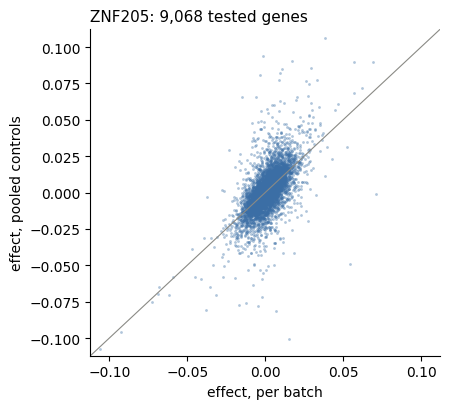

In [8]:
worst = int(np.argmax(np.where(kept, np.nanmean(np.where(both, gap, np.nan), axis=1), -np.inf)))
fig, ax = plt.subplots(figsize=(4.6, 4.2))
x, y = effect[worst, both[worst]], by_pool.X[worst, both[worst]]
ax.scatter(x, y, s=4, alpha=0.4, color='#3b6ea5', linewidths=0)
lim = np.nanpercentile(np.abs(np.concatenate([x, y])), 99.9)
ax.plot([-lim, lim], [-lim, lim], color='#8a8a85', linewidth=0.8)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel('effect, per batch')
ax.set_ylabel('effect, pooled controls')
ax.set_title(f'{by_batch.obs_names[worst]}: {both[worst].sum():,} tested genes', loc='left', fontsize=11)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
plt.tight_layout()

### 6. Do the standard errors agree with the rank test?

The effect divided by its standard error is a z-score; if the standard error is right, it should follow
the Wilcoxon z-score, which makes no distributional assumption. For each target, the correlation of
the two over its tested genes:

In [9]:
z_wilcoxon = wilcoxon['per batch'].layers['z_score']
agreement = {}
for name, standard_error in (('standard error', se), ('robust standard error', se_robust)):
    z = effect / standard_error
    r = [np.corrcoef(z[i, ok], z_wilcoxon[i, ok])[0, 1]
         for i in np.flatnonzero(kept) if (ok := tested[i] & np.isfinite(z[i])).sum() > 2]
    agreement[name] = {'median r with Wilcoxon z': np.median(r),
                       'median |z| / |Wilcoxon z|': np.nanmedian(np.abs(z[kept] / z_wilcoxon[kept]))}
pd.DataFrame(agreement).T.round(3)

,median r with Wilcoxon z,median |z| / |Wilcoxon z|
standard error,0.922,1.347
robust standard error,0.926,1.057


### 7. Calibration on fake targets

A test is calibrated when it rarely reports hits where there is no effect. Fake targets are made of
non-targeting guides, as in the [CD4+ T-cell tutorial](residual_effects_tutorial.ipynb): the 20
non-targeting guides are shuffled and six fake targets of three guides are formed (the size of a real
target); the other two guides stay controls. A fake target has no knockdown, but its cells keep the
differences between guides and batches that real targets have. Five random splits go through both
calls; for a calibrated test, 5% of p-values fall below 0.05.

In [10]:
non_targeting = sorted(guide[guide.str.startswith('NonTarget')].unique())
rng = np.random.default_rng(0)
fake_tests = {name: [] for name in ('Wilcoxon, per batch', 'effect / standard error', 'effect / robust standard error')}
with measured('fake targets, 5 splits'), warnings_as_messages():
    for split in range(5):
        order = rng.permutation(non_targeting)
        fake = labels.copy()
        names = []
        for k in range(6):
            name = f'fake{k}'
            fake[guide.isin(order[3 * k:3 * k + 3]).to_numpy()] = name
            names.append(name)
        fake_common = dict(perturbation_column=fake, control_label='control', perturbations=names,
                           gene_name_column='gene_name', verbose=0)
        eff = ad.read_h5ad(cx.pb.normalized_effects(
            counts_path, batch_column=strata, output_path=OUTPUT_DIR / f'fengts_fake{split}_effects.h5ad',
            **fake_common).path)
        wil = ad.read_h5ad(cx.wilcoxon_test(
            normalised_path, batch_column='batch', output_path=OUTPUT_DIR / f'fengts_fake{split}_wilcoxon.h5ad',
            **fake_common, **FILTER).result_path)[eff.obs_names]
        ok = np.isfinite(wil.layers['pvalue'])
        fake_tests['Wilcoxon, per batch'].append(wil.layers['pvalue'])
        for name, layer in (('effect / standard error', 'standard_error'),
                            ('effect / robust standard error', 'standard_error_robust')):
            fake_tests[name].append(np.where(ok, 2 * stats.norm.sf(np.abs(eff.X / eff.layers[layer])), np.nan))

calibration = {}
for name, blocks in fake_tests.items():
    p = np.vstack(blocks)
    q = np.full(p.shape, np.nan)
    for i in range(p.shape[0]):
        ok = np.isfinite(p[i])
        q[i, ok] = stats.false_discovery_control(p[i, ok])
    fake_hits = (q < 0.05).sum(axis=1)
    calibration[name] = {'p < 0.05': np.nanmean(p < 0.05) / np.mean(np.isfinite(p)),
                         'hits per fake target, median': np.median(fake_hits),
                         'hits per fake target, mean': fake_hits.mean()}
pd.DataFrame(calibration).T.round(3)

fake targets, 5 splits: 32.9 min, peak RSS 105.2 GB


,p < 0.05,"hits per fake target, median","hits per fake target, mean"
"Wilcoxon, per batch",0.060,1.5,2.167
effect / standard error,0.149,143.5,138.567
effect / robust standard error,0.066,4.5,4.233


The rank test and the robust standard error stay close to the nominal 5%, with a median of 1.5 and
4.5 hits per fake target. The model-based standard error does not: 14.9% of p-values fall below 0.05
and a fake target gets about 140 hits. It assumes the cells of a batch are independent, but cells that
carry one guide share whatever that guide does besides its knockdown, and each guide spans hundreds of
batches. The robust standard error is read from how much the per-batch effects actually scatter, so it
takes this in; it is 1.22 times the model-based one for a typical target (step 2).

### 8. Against `residual_effects`

`residual_effects` estimates a similar quantity another way: each gene is fitted to the covariates on the
control cells, and a target's effect is the mean residual of its cells. With inlet and line as
covariates (added, not crossed into 1,325 batches) and the `"model"` null:

In [11]:
with measured('residual_effects, inlet + line'):
    residual = cx.tl.residual_effects(
        counts_path, labels, 'control', covariates=['inlet', 'line'], null='model', min_cells=20,
        gene_name_column='gene_name', output_path=OUTPUT_DIR / 'fengts_residual_inlet_line.h5ad',
    )
res = ad.read_h5ad(residual.path)[by_batch.obs_names]
ok = tested & np.isfinite(res.X)
r = [np.corrcoef(effect[i, ok[i]], res.X[i, ok[i]])[0, 1] for i in np.flatnonzero(kept)]
slope = [np.polyfit(effect[i, ok[i]], res.X[i, ok[i]], 1)[0] for i in np.flatnonzero(kept)]
res_hits = (adjusted(np.where(tested, res.layers['pvalue'], np.nan)) < 0.05)[kept].sum(axis=1)
print(f'per target, residual_effects against the per-batch effect: median r {np.median(r):.3f}, '
      f'median slope {np.median(slope):.3f}; hits per target, median {np.median(res_hits):.0f}')

[cx] residual_effects: Reading tutorial_outputs/FengTS_counts.h5ad
[cx] residual_effects: 444 perturbations, 535,083 control cells, design: 160 columns
[cx] residual_effects: the design has rank 159 < 160 columns (collinear covariates); every perturbation's design lies within the controls', so its effect is still unique.
[cx] residual_effects: estimated disk usage: 570.7 MB (366.0 GB free)
[cx] residual_effects: 444 perturbations x 36,518 genes (8,192 tested), model null
[cx] residual_effects: Saving → tutorial_outputs/fengts_residual_inlet_line.h5ad
residual_effects, inlet + line: 0.5 min, peak RSS 22.2 GB
per target, residual_effects against the per-batch effect: median r 0.999, median slope 0.999; hits per target, median 100


The effects agree almost exactly, though the two weigh batches differently: `residual_effects`
averages residuals over cells, so a batch counts by its number of target cells, and it adds inlet and
line effects instead of crossing them. Its hits are counted over the genes it tests (control mean
above 0.1), with a null that, like the model-based standard error, treats cells as independent.

## Resources

Wall time and peak memory of this notebook's process for each step.

In [12]:
resources = pd.DataFrame(steps).set_index('step')
resources.loc['total'] = [resources['wall time (min)'].sum(), resources['peak RSS (GB)'].max()]
resources

,wall time (min),peak RSS (GB)
step,,
"effects and standard errors, per batch",8.5,203.1
"effects, pooled",4.1,17.1
normalise for the rank test,0.9,13.1
"wilcoxon_test, per batch",4.4,100.9
"wilcoxon_test, pooled",3.9,97.7
"fake targets, 5 splits",32.9,105.2
"residual_effects, inlet + line",0.5,22.2
total,55.2,203.1


In [13]:
normalised_path.unlink()  # the normalised copy, 48 GB, is not needed again

## Takeaways

- **For a screen run in many batches, compare each batch with its own controls:**
  `cx.pb.normalized_effects(..., batch_column=...)` for effects and standard errors,
  `cx.wilcoxon_test(..., batch_column=...)` for p-values. Against all controls at once, differences in
  batch composition pass for effects.
- **Use the robust standard error** (`standard_error_robust`) for z-scores or to weight effects
  downstream: here it is close to calibrated and on the rank test's scale. The model-based one is too
  small when the cells of a guide or donor move together.
- **Fine batches cost memory:** 444 targets over 1,325 batches made 347,000 (target, batch) sums of
  36,518 genes, a 203 GB peak. With a smaller `memory_limit_gb` they go to temporary files on disk.
- **To adjust for continuous covariates as well** (depth, cell cycle), use `residual_effects`; see the
  [`residual_effects` in a targeted screen](residual_effects_feng_tutorial.ipynb).